# Hurricane Tracker -- Interactive
This demonstrates the use of input and display widgets in a Jupyter Notebook

In [2]:
# Import packages
from pathlib import Path
import pandas as pd
import seaborn as sns
import ipywidgets as widgets
import matplotlib.pyplot as plt
from IPython.display import display, clear_output

# GIS pakcages
from arcgis import GIS
from arcgis.features import FeatureLayer
from arcgis.geometry import Polyline
from arcgis.geometry.filters import intersects

# Initialize ArcGIS GIS connection
gis = GIS('home')

# Disable URL warnings
import urllib3
urllib3.disable_warnings()

#Set paths
raw_folder_path = Path.cwd().parent / 'data' / 'raw'
processed_folder_path = Path.cwd().parent / 'data' / 'processed'

In [3]:
#Set model layers
ibtracs_NA_points = raw_folder_path /'IBTrACS_NA.shp'
if not ibtracs_NA_points.exists():
    print('ibtracs_NA_points.shp file not found.\nBe sure you have unzipped the file.')
    
usa_counties = 'https://services.arcgis.com/P3ePLMYs2RVChkJx/arcgis/rest/services/USA_Counties_Generalized_Boundaries/FeatureServer/0'

In [4]:
#Convert storm point feature class to spatial dataframe
sdf_allstorms = pd.DataFrame.spatial.from_featureclass(ibtracs_NA_points)

In [5]:
#Create a spatial dataframe from the counties
counties_lyr = FeatureLayer(usa_counties,gis=gis)

In [6]:
#Function to extract affected counties for a given season and name
def get_affected_counties(the_season, the_name):
    #Select the points
    sdf_storm_points = sdf_allstorms.loc[
        (sdf_allstorms['SEASON']==the_season) &
        (sdf_allstorms['NAME']==the_name)
        ]

    #Sort points on ISO_TIME
    sdf_storm_points = sdf_storm_points.sort_values(by='ISO_TIME')

    #Create a storm track line from the points
    coords = [[geom.x, geom.y]  for geom in sdf_storm_points["SHAPE"]]
    track_line = Polyline({
        'paths':[coords],
        'spatialReference':sdf_storm_points.spatial.sr
    })

    #Query the counties feature layer for records intersecting the track line geometry
    intersecting_counties = counties_lyr.query(
        geometry_filter=intersects(track_line)
    ).sdf

    return intersecting_counties


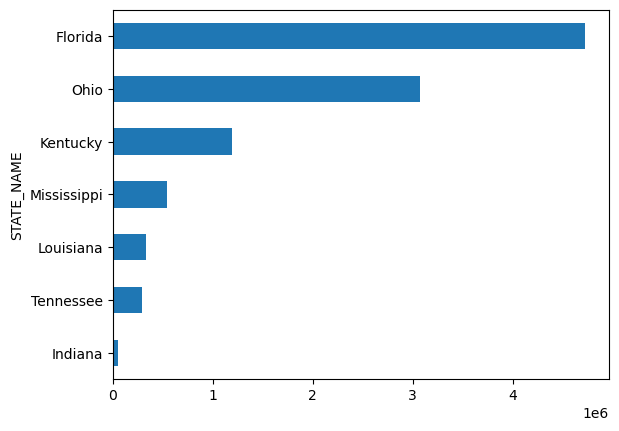

In [14]:
#Get a sample output
the_season = 2005
the_name = 'KATRINA'
sdf_affected_counties = get_affected_counties(the_season, the_name)
#Plot
sdf_affected_counties.groupby('STATE_NAME')['POPULATION'].sum().sort_values().plot.barh();